<a href="https://colab.research.google.com/github/RobertoSonzini/NAML_project/blob/main/Progetto_NAML_Dataset_variation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Progetto NAML**

## **TODO**:
- FUNZIONI E MANCANZE:

  - Aggiunta di qualche analisi in più dei dati?
  - Mancano le loss nell' ANN
  - Cross-validation?
  - Nelle implementazioni fom scratch provare ad usare Adam o cose simili?
  - Considerazione sul fatto che i modelli più semplici a partià di epoche etc. hanno performances migliori.

- COMMENTI E ALTRO (bellezza e organizzazione del notebook):
  - Risistemare l'ordine dei modelli. (idealmente dal più semplice al più complesso)
  - Aggiungere nell'LSTM from scratch la breve spiegazione delle celle LSTM.
  - Aggiungere nell'LSTM from scratch immagine della cella LSTM.
  - Aggiungere immagini per tutte le reti che specificano i layers.
  - Aggiungere formule LATEX per bellezza.

 (NB: tutte le immagini ci possono servire anche per poi metterle nella presentazione)

1. Analisi esplorativa (EDA – Exploratory Data Analysis)

Distribuzione statistica: controlla media, deviazione standard, skewness, kurtosis di Close, Open, High, Low, Volume.

Correlazioni: heatmap delle correlazioni tra feature e prezzo di chiusura (ad esempio Pearson/Spearman).

Visualizzazione temporale: grafici lineari del Close nel tempo → utile per capire trend e volatilità.

Stazionarietà: test di Dickey-Fuller per vedere se la serie ha trend o stagionalità (se non è stazionaria, spesso serve differenziare o log-transformare).

2. Qualità dei dati

Valori mancanti: quanti ce ne sono? Come imputarli (forward fill, backward fill, interpolazione).

Outlier: picchi anomali nel volume o nel prezzo.

Granularità temporale: i dati sono giornalieri, orari o minuti? Ci sono “buchi” nei giorni di mercato?

3. Struttura temporale

Autocorrelazione: controlla ACF/PACF per capire fino a che lag il prezzo dipende dai valori precedenti.

Volatilità: calcola la rolling volatility e vedi se cambia nel tempo.

Pattern stagionali: ci sono effetti settimanali/mensili/annuali?

4. Feature Engineering

Genera indicatori tecnici (SMA, EMA, RSI, MACD, Bollinger Bands).

Feature di volatilità (rolling std, log returns).

Trasformazioni sui prezzi: log-return invece del livello di prezzo → spesso più prevedibile.

5. Valutazione di “predicibilità”

Prima ancora di allenare una rete:

Fai un modello di baseline semplice (es. persistenza: predire che il prezzo di domani = prezzo di oggi).

Prova una regressione lineare o un ARIMA e confronta le performance.

Se le baseline non battono il caso banale → forse il dataset non contiene abbastanza segnale predittivo.

6. Split dei dati

Niente shuffle casuale (sarebbe leakage!) → fai train/test split temporale (es. primi 70% train, ultimi 30% test).

Eventualmente anche una time series cross-validation (walk-forward validation).  


  In pratica, lo “studio” che dovresti fare si chiama analisi esplorativa della serie temporale (time series EDA) + valutazione della predicibilità.
  Solo dopo puoi capire se il dataset ha senso per reti neurali complesse.

## **Project Overview**

In recent years, deep learning techniques have demonstrated remarkable success in a wide range of fields, including financial forecasting.

Our project takes inspiration from the work of *Zhang et al. (2019), “Stock Market Prediction Based on Generative Adversarial Network”*, in which the authors propose a novel Generative Adversarial Network (GAN) architecture tailored for stock price forecasting. Their framework combines a **Long Short-Term Memory (LSTM)** network, acting as the **generator**, with a **Multi-Layer Perceptron (MLP)**, acting as the **discriminator**. The **LSTM** is particularly well-suited for handling sequential data, as it can capture temporal dependencies in stock prices, while the **MLP** effectively distinguishes between real and generated data distributions.

Building on this foundation, our work seeks to reproduce and adapt similar ideas, with the aim of exploring the potential of GAN-based architectures for predicting the daily closing price of stocks. In addition to implementing this adversarial approach, we also conducted a comparative analysis with more classical models, including a standalone **LSTM**, a standard Artificial Neural Network (**ANN**), and a regression Support Vector Machine (**SVR**). This comparison allows us to better evaluate the advantages and limitations of the GAN-based strategy in relation to widely used machine learning techniques.

## **Imports**

In [ ]:
!pip uninstall torch
!pip cache purge
!pip install torch --upgrade

Found existing installation: torch 2.8.0+cu126
Uninstalling torch-2.8.0+cu126:
  Would remove:
    /usr/local/bin/torchfrtrace
    /usr/local/bin/torchrun
    /usr/local/lib/python3.12/dist-packages/functorch/*
    /usr/local/lib/python3.12/dist-packages/torch-2.8.0+cu126.dist-info/*
    /usr/local/lib/python3.12/dist-packages/torch/*
    /usr/local/lib/python3.12/dist-packages/torchgen/*
Proceed (Y/n)? 

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
import torch
from torch import nn
import math
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

import jax
import jax.numpy as jnp
from jax import grad, jit, vmap, lax
from jax import random
from jax.nn import sigmoid

from datetime import datetime

plt.rcParams['lines.linewidth'] = 2

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [ ]:
import jax
import jax.numpy as jnp
import jax.scipy.optimize

import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

## **Dataset study**

Here we mount **Google Drive** to access the dataset, load the **CSV file** containing stock data into a **Pandas DataFrame**, and display basic information about its structure and contents.

As we can observe from the output of the following code, the dataset contains 619,040 entries and 7 columns, which include the **date, stock prices (open, high, low, close), trading volume, and the company name**. Most columns are complete, with only a few missing values in the price-related fields. The dataset occupies about 33 MB of memory.

Moreover, this dataset appears suitable for reproducing the work described in the paper, as it provides several of the required features **(high, low, open, close, and volume)** which align with those mentioned in the paper **(high, low, open, close, turnover_rate, volume, and MA5)**.

Unfortunately, the **turnover_rate** parameter is not available in this dataset, but the **MA5** (5-day moving average) can be computed and therefore will be added to our data.

In [ ]:
file_path = '/content/drive/MyDrive/ProgettoNAML/all_stocks_5yr.csv'
drive.mount('/content/drive')

df = pd.read_csv(file_path)
df.head()

%matplotlib inline

df.info()
df

In [ ]:
df.info()

In [ ]:
latest_date = pd.to_datetime(df['date']).max()

one_year_before = latest_date - pd.DateOffset(years=1)

date_series = pd.to_datetime(df['date'])
mask = (date_series >= one_year_before) & (date_series <= latest_date) & (df['Name'] == 'AAPL')

filtered_df = df[mask]
filtered_df['date'] = pd.to_datetime(filtered_df['date'])

In [ ]:
plt.figure(figsize=(10,6))
plt.plot(filtered_df['date'], filtered_df['close'])
plt.ylabel('Close Price')
plt.xlabel('Date')
plt.title("Closing Price of Apple (AAPL)")

step = 30

plt.xticks(ticks=filtered_df['date'][::step], labels=filtered_df['date'].dt.strftime('%Y-%m')[::step], rotation=45)

plt.grid(True)
plt.tight_layout()

plt.show()

In [ ]:
plt.figure(figsize=(10,6))
plt.plot(filtered_df['date'], filtered_df['volume'])
plt.ylabel('Volume')
plt.xlabel('Date')
plt.title("Volume of Apple (AAPL)")

step = 30

plt.xticks(ticks=filtered_df['date'][::step], labels=filtered_df['date'].dt.strftime('%Y-%m')[::step], rotation=45)

plt.grid(True)
plt.tight_layout()

plt.show()

In our dataset, one of the features is the trading **volume** of a given company. Since trading volume can be highly variable and often includes extreme values, it is particularly prone to **outliers**. To mitigate this issue, we later apply a logarithmic transformation to obtain the **log-volume**. This approach helps normalize the distribution, reduce skewness, and improve the stability of the feature, making it more suitable for predictive modeling.

In [ ]:
ma_day = [0, 10, 20, 50]
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))

for i, ma in enumerate(ma_day):
    df_copy = filtered_df.copy()
    df_copy['ma_close'] = df_copy['close'].rolling(ma).mean()

    ax = axes[i // 2, i % 2]

    ax.plot(df_copy['date'], df_copy['close'], label='Closing Price')

    ax.plot(df_copy['date'], df_copy['ma_close'], label=f'{ma}-Day Moving Average', color='orange')

    ax.set_ylabel('Close Price')
    ax.set_xlabel('Date')
    ax.set_title(f"Closing Price of Apple (AAPL) with {ma}-Day Moving Average")
    ax.legend()

    step = 30
    ax.set_xticks(df_copy['date'][::step])
    ax.set_xticklabels(df_copy['date'].dt.strftime('%Y-%m')[::step], rotation=45)

    ax.grid(True)

plt.tight_layout()
plt.show()

## **Dataset setup**

In [ ]:
df.head()

### **Complete the dataset**

After importing and analyzing the dataset, we conducted a **correlation study** and observed that several features were highly correlated with the **target variable**, in some cases with correlation values approaching 1. This is because, in the original dataset, the target variable at time *t* corresponds to the closing price at the same time, making it **directly dependent** on other data from that day.

From a **predictive perspective**, we therefore shifted the closing price (target) column so that, at each time *t*, it represented the closing price at time *t+1*. Given the relatively **low** day-to-day **variability**, this adjustment still resulted in a very high correlation between the input features and the target.

Although this could lead to very high predictive accuracy, it would not have provided **meaningful insights**, as the model would effectively learn trivial linear relationships. To address this, we modified the dataset to ensure that the relationship between the features and the target was not purely linear, allowing the model to capture more **informative and robust patterns**.

With the following code, we filter the original dataset to include data from a single company. At the same time, we complete the dataset by adding the missing fields required for our analysis.

In [ ]:
def sort_by_date(df):
  return df.sort_values(by='date')

In [ ]:
def get_dataframe_full(df, company_names, moving_average=5):
    input_data_labels = ['high', 'low', 'open', 'volume', 'close', 'ma5']
    close_data = ['close']

    mask = df['Name'].isin(company_names)
    df_company = df.loc[mask].copy()

    df_company['ma5'] = df_company['close'].rolling(moving_average).mean()

    df_company = df_company.dropna()

    df_company = sort_by_date(df_company)

    return df_company[input_data_labels]

In [ ]:
def prepare_dataset_for_forecast(df, company_names, moving_average=5, shift = 1):
    df_company = get_dataframe_full(df, company_names, moving_average)

    df_company['return'] = df_company['close'].pct_change()
    df_company['high_low'] = df_company['high'] - df_company['low']
    df_company['close_open'] = df_company['close'] - df_company['open']
    df_company['log_volume'] = np.log(df_company['volume'] + 1)
    df_company[f'ma{moving_average}'] = df_company['close'].rolling(moving_average).mean()

    df_company['target_close'] = df_company['close'].shift(-shift)

    df_company = df_company.drop(columns=['close'])

    df_company = df_company.rename(columns={'target_close': 'close'})

    df_company = df_company.dropna()

    return df_company

In [ ]:
def get_dataframe(df, company_names, moving_average=5):
    df_forecasting = prepare_dataset_for_forecast(df, company_names, moving_average)
    input_data_labels = ['return', 'high_low', 'close_open', 'log_volume', f'ma{moving_average}']

    close_data = ['close']
    return df_forecasting[input_data_labels], df_forecasting[close_data]

In [ ]:
def get_dataframe_mod(df, company_names, moving_average=5, shift = 1):
    df_forecasting = prepare_dataset_for_forecast(df, company_names, moving_average, shift)
    input_data_labels = ['return', 'high_low', 'close_open', 'log_volume', f'ma{moving_average}', 'close']

    close_data = ['close']
    return df_forecasting[input_data_labels], df_forecasting[close_data]

In [ ]:
df_apple, apple_closings = get_dataframe(df, ['AAPL'])
df_apple.head()

In [ ]:
df_apple.shape[0]

### **Correlation**

In [ ]:
def plot_correlations(df, method='pearson'):
    corr = df.corr(method=method)

    plt.figure(figsize=(8,6))
    sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
    plt.title(f"Correlation heatmap ({method})", fontsize=14)
    plt.show()

    corr_with_close = corr['close'].drop('close').sort_values(ascending=False)
    print("Correlation with 'close':\n")
    print(corr_with_close)

In [ ]:
df_company_full, _ = get_dataframe_mod(df, ['AAPL'])
plot_correlations(df_company_full, method='pearson')

The following analysis studies **how explanatory variables** (such as ma5, high_low, close_open, return, log_volume) **correlate with the future value of the target** (close) as the time shift varies. For each lag (t+1, t+2, ...), the linear correlation between the features observed at time t and the price at time t+lag is calculated. In this way, it is possible to understand to what extent the **information contained** in the variables retains **predictive power** in the future. This approach provides useful information for selecting the sequence length in sequential models such as LSTMs and helps to identify which features maintain a significant relationship with the target over different time horizons, avoiding both sequences that are too short, which would lose information, and sequences that are too long, which would introduce noise.

In [ ]:
def plot_correlations_with_close(df, method='pearson'):
    corr = df.corr(method=method)
    corr_with_close = corr['close'].drop('close').sort_values(ascending=False)
    return corr_with_close

In [ ]:
corr_matrix = {}
for i in range(0, 50):
  df_company_correlation, _ = get_dataframe_mod(df, ['AAPL'], shift = i)
  corr_with_close = plot_correlations_with_close(df_company_correlation, method='pearson')
  corr_matrix[i] = corr_with_close

df_corr = pd.DataFrame.from_dict(corr_matrix, orient="index")
fig, axs = plt.subplots(5, 1, figsize=(12, 12), sharex=False)

cols = ["ma5", "high_low", "close_open", "return", "log_volume"]

for i, col in enumerate(cols):
    axs[i].plot(df_corr.index, df_corr[col], marker="o")
    axs[i].set_title(col)
    axs[i].grid(True)
    axs[i].set_xticks(df_corr.index)
    axs[i].set_xticklabels(df_corr.index)


plt.tight_layout()
plt.show()

# **Networks**

## **ANN**

Here we implement a simple **ANN** using the PyTorch framework.

### **Preparation of data**

In this step, we prepare the dataset for model training and testing:

 - **Standardization**: We use StandardScaler from sklearn.preprocessing to normalize the data. Standardization ensures that all features have **zero mean** and **unit variance**, which helps many machine learning models converge faster and perform better.
 - **Train-Test Split**: The dataset is split into training and testing sets, with **90%** of the data used for training and the remaining **10%** for testing. This split ensures that the model can be trained on the majority of the data while still being evaluated on unseen samples. We chose a 90-10 split because using a smaller training set did not allow the network to achieve the same level of accuracy, likely due to the relatively small number of data points available for the selected company.

In [ ]:
scaler = StandardScaler()

df_company, company_closings = get_dataframe(df, ["AAPL"])
df_company, company_closings = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index), pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)

length = len(df_company)
split_idx = int(length * 0.9)

df_company_train = df_company.iloc[:split_idx]
df_company_closings_train = company_closings.iloc[:split_idx]
df_company_test = df_company.iloc[split_idx:]
df_company_closings_test = company_closings.iloc[split_idx:]

X_train = df_company_train.to_numpy().astype(np.float32)
y_train = df_company_closings_train.to_numpy().astype(np.float32)
X_test = df_company_test.to_numpy().astype(np.float32)
y_test = df_company_closings_test.to_numpy().astype(np.float32)

This class defines a custom PyTorch dataset for sequence data.
This class will be used to create a **data loader** that provides the inputs as **(batch_size, input_size)** and the labels as **(batch_size, number of target features)**. This structure is necessary because, in this implementation, we use PyTorch libraries that require data to have these shapes.

In [ ]:
class MyANNDataset(Dataset):
    def __init__(self, X_data, y_data):
      self.X_data = X_data
      self.y_data = y_data

    def __len__(self):
      return len(self.y_data)

    def __getitem__(self, idx):
      x = self.X_data[idx]
      y = self.y_data[idx]

      return x, y

### **Pytorch ANN implementation**

Here we provide the PyTorch implementation of the ANN. The network size was chosen arbitrarily. Specifically, it consists of three **fully connected layers** with **LeakyReLU** activation functions. The input passes through a hidden layer of **64** neurons, and the output layer produces a single value, corresponding to the closing price.

In [ ]:
class ANN(nn.Module):
  def __init__(self, input_size):
    super(ANN, self).__init__()
    self.ann = nn.Sequential(
      nn.Linear(input_size, 64),
      nn.LeakyReLU(),
      nn.Linear(64, 1)
  )

  def forward(self, x):
    # input size x: (batch_size, n_features)
    return self.ann(x)

### **Setting the hyperparameters**

Here we define the **hyperparameters** that were found empirically to give the best results.

In [ ]:
input_size = 5
num_epochs = 10
lr = 0.001

model = ANN(input_size)
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

### **Training**

At this stage, having chosen the **hyperparameters**, we perform the training of the network using PyTorch’s compact framework.

In [ ]:
def train_ANN(model, epochs, loss_function, optimizer):
  dataset = MyANNDataset(X_train, y_train)
  loader_ANN = DataLoader(dataset, batch_size=32, shuffle=True)

  n_total_steps = len(loader_ANN)

  model.to(device)
  model.train()
  losses = []

  for epoch in range(epochs):
    epoch_loss = 0
    for i, (samples, labels) in enumerate(loader_ANN):
      samples = samples.to(device)
      labels = labels.to(device)

      # Forward pass
      outputs = model(samples)
      loss = loss_function(outputs, labels)
      epoch_loss += loss.item()
      losses.append(loss.item())

      # Backward and optimize
      loss.backward()
      optimizer.step()
      optimizer.zero_grad()
    epoch_loss /= len(loader_ANN)
    print(f'Epoch [{epoch+1}/{epochs}], Step [{i+1}/{n_total_steps}], Loss: {epoch_loss:.4f}')
  return losses

In [ ]:
ANN_losses = train_ANN(model, num_epochs, loss_function, optimizer)

### **Learning of our ANN**

In [ ]:
plt.figure(figsize=(15, 5))
plt.plot(ANN_losses, label = "loss")

plt.title("ANN loss trend")
plt.xscale("log")

plt.grid(True)

plt.show()

### **Testing**

In [ ]:
def test_ANN(model, loss_function):
  dataset = MyANNDataset(X_test, y_test)
  loader_ANN = DataLoader(dataset, batch_size=32, shuffle=False)

  model.eval()
  total_loss = 0
  preds = []
  actuals = []

  with torch.no_grad():
    for i, (x_batch, y_batch) in enumerate(loader_ANN):
      x_batch = x_batch.to(device)
      y_batch = y_batch.to(device)

      outputs = model(x_batch)
      loss = loss_function(outputs, y_batch)

      total_loss += loss.item() * x_batch.size(0)

      preds.extend(outputs.cpu().numpy())

    actuals = y_test
    avg_loss = total_loss / len(loader_ANN.dataset)
    print(f"Test Loss: {avg_loss:.4f}")

  return preds, actuals

In [ ]:
preds_ANN, actuals_ANN = test_ANN(model, loss_function)

### **Prediction results vs. true data**

The following graph illustrates the predictions made by our **ANN** model compared to the actual data. As can be observed, the predicted values closely follow the trends of the true data, indicating that the model has successfully learned the underlying patterns. This demonstrates a good level of accuracy and confirms the effectiveness of our training process.

In [ ]:
def plot_predictions(preds, actuals):
  plt.figure(figsize=(10, 6))
  plt.plot(actuals, label='True')
  plt.plot(preds, label='Predicted')
  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

In [ ]:
plot_predictions(preds_ANN, y_test)

##**SVM**

In [308]:
df_company, company_closings = get_dataframe(df, ["AAPL"])

scaler = StandardScaler()
df_company, company_closings = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index), pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)



length = len(df_company)
split_idx = int(length * 0.9)

df_company_train = df_company.iloc[:split_idx]
df_company_closings_train = company_closings.iloc[:split_idx]
df_company_test = df_company.iloc[split_idx:]
df_company_closings_test = company_closings.iloc[split_idx:]

X_train = df_company_train.to_numpy().astype(np.float32)
y_train = df_company_closings_train.to_numpy().astype(np.float32)
X_test = df_company_test.to_numpy().astype(np.float32)
y_test = df_company_closings_test.to_numpy().astype(np.float32)

In [309]:
class SVR:
    def __init__(self, epsilon=0.1, C=1.0):
        self.epsilon = epsilon
        self.C = C
        self.params = None

    def loss(self, params, X, y):
        w, b = params[:-1], params[-1]
        preds = X @ w + b

        # Compute epsilon-insensitive loss
        r = jnp.abs(preds - y.squeeze())
        eps_loss = jnp.maximum(0.0, r - self.epsilon)

        # Total loss
        return 0.5 * jnp.sum(w*w) + self.C * jnp.mean(eps_loss)

    def train(self, X, y):
        X = jnp.asarray(X)
        y = jnp.asarray(y).squeeze()
        n_features = X.shape[1]
        init = jnp.zeros(n_features + 1)  # w + b
        res = jax.scipy.optimize.minimize(self.loss, init, method="BFGS", args=(X, y))
        self.params = res.x


    def predict(self, X):
        w, b = self.params[:-1], self.params[-1]
        return jnp.asarray(X) @ w + b

In [310]:
# Convert data to JAX arrays
X_train = jnp.array(X_train)
y_train = jnp.array(y_train)
X_test = jnp.array(X_test)
y_test = jnp.array(y_test)

In [321]:
svr = SVR(epsilon=0.1, C=1.5)
svr.train(X_train, y_train)
y_pred_train = svr.predict(X_train)
y_pred_test = svr.predict(X_test)

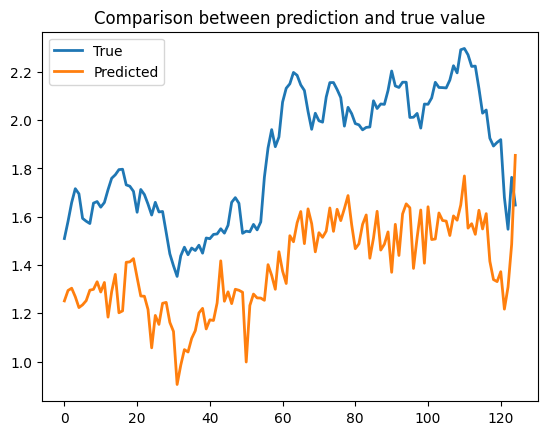

In [322]:
def plot_predictions(preds, actuals):
  plt.plot(actuals, label='True')
  plt.plot(preds, label='Predicted')
  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

plot_predictions(y_pred_test, y_test)

In [323]:
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import numpy as np

# Supponiamo che X, y siano i tuoi dati
# X = df_company.values
# y = company_closings.values.flatten()

# Scaling (importantissimo per SVR!)
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y.reshape(-1, 1)).flatten()

# Split in train/test
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_scaled, test_size=0.2, random_state=42)

# Modello SVR con RBF kernel
svr_model = SVR(epsilon=0.1, C=1.5, kernel='rbf')
svr_model.fit(X_train, y_train)

# Predizioni
y_pred_scaled = svr_model.predict(X_test)

# Riportiamo le predizioni alla scala originale
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()
y_true = scaler_y.inverse_transform(y_test.reshape(-1, 1)).flatten()

# Valutazione
mse = mean_squared_error(y_true, y_pred)
print("MSE:", mse)

NameError: name 'X' is not defined

## **LSTM (with Pytorch)**

Here we implement the **LSTM** using the **PyTorch** library, which provides **high-level modules** for defining the network and handling training efficiently.

### **Preparation of data**

In this step, we prepare the dataset for model training and testing:

 - **Standardization**: We use StandardScaler from sklearn.preprocessing to normalize the data. Standardization ensures that all features have **zero mean** and **unit variance**, which helps many machine learning models converge faster and perform better.
 - **Train-Test Split**: The dataset is split into training and testing sets, with **90%** of the data used for training and the remaining **10%** for testing. This split ensures that the model can be trained on the majority of the data while still being evaluated on unseen samples. We chose a 90-10 split because using a smaller training set did not allow the network to achieve the same level of accuracy, likely due to the relatively small number of data points available for the selected company.

In [ ]:
scaler = StandardScaler()

df_company, company_closings = get_dataframe(df, ['AAPL'])
df_company, company_closings = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index), pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)

length = len(df_company)
split_idx = int(length * 0.9)

df_company_train = df_company.iloc[:split_idx]
df_company_closings_train = company_closings.iloc[:split_idx]
df_company_test = df_company.iloc[split_idx:]
df_company_closings_test = company_closings.iloc[split_idx:]

X_train = df_company_train.to_numpy().astype(np.float32)
y_train = df_company_closings_train.to_numpy().astype(np.float32)
X_test = df_company_test.to_numpy().astype(np.float32)
y_test = df_company_closings_test.to_numpy().astype(np.float32)

This class defines a custom PyTorch dataset for sequence data.
This class will be used to create a **data loader** that provides the inputs as **(batch_size, seq_len, input_size)** and the labels as **(batch_size, number of target features)**. This structure is necessary because, in this implementation, we use PyTorch libraries that require data to have these shapes.

In [ ]:
class MyDataset(Dataset):
  def __init__(self, X_data, y_data, seq_len = 1):
    self.X_data = X_data
    self.y_data = y_data
    self.seq_len = seq_len

  def __len__(self):
    return len(self.y_data) - self.seq_len

  def __getitem__(self, idx):
    x = self.X_data[idx : idx + self.seq_len]
    y = self.y_data[idx + self.seq_len]
    return x, y

### **Pytorch LSTM implementation**

This is our PyTorch implementation of an LSTM model for time series prediction. The architecture consists of the following components:

 - **LSTM Layer**: Processes the input sequences and captures temporal dependencies
  - *input_size* specifies the number of features in each time step.
  - *hidden_size* is the number of features in the hidden state, controlling the model’s capacity to learn patterns.
  - *num_layers* allows stacking multiple LSTM layers to capture more complex sequential patterns.
  - *batch_first*=True ensures that the input tensor has shape (batch_size, seq_len, input_size), which aligns with our dataset loader.
  - *dropout*=0.3 applies dropout between LSTM layers (if stacked) to reduce overfitting.

 - **Fully Connected Layer**: Maps the hidden state of the last time step to the output prediction. Since we are predicting a single value (the **closing price**), the output dimension is 1.

In [ ]:
class LSTM(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers):
      '''
        From pyorch documentation:
        * input_size – The number of expected features in the input x
        * hidden_size – The number of features in the hidden state h
        * num_layers – Number of recurrent layers.
          E.g., setting num_layers=2 would mean stacking two LSTMs together to form a stacked LSTM, with the second LSTM taking in outputs of the first LSTM and computing the final results. Default: 1

        * bias – If False, then the layer does not use bias weights b_ih and b_hh. Default: True
        * batch_first – If True, then the input and output tensors are provided as (batch, seq, feature) instead of (seq, batch, feature). Note that this does not apply to hidden or cell states. See the Inputs/Outputs sections below for details. Default: False
        * dropout – If non-zero, introduces a Dropout layer on the outputs of each LSTM layer except the last layer, with dropout probability equal to dropout. Default: 0
        * bidirectional – If True, becomes a bidirectional LSTM. Default: False
        * proj_size – If > 0, will use LSTM with projections of corresponding size. Default: 0
      '''
      super(LSTM, self).__init__()
      self.num_layers = num_layers
      self.hidden_size = hidden_size
      self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=0.3)
      self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
      # -> x needs to be: (batch_size, seq_len, input_size)
      # Set initial hidden states (and cell states for LSTM)
      h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size)
      c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size)

      # Forward propagate LSTM
      out, _ = self.lstm(x, (h0,c0))

      # out: tensor of shape (batch_size, seq_len, hidden_size)

      # Decode the hidden state of the last time step
      out = out[:, -1, :]
      out = self.fc(out)

      return out

### **Setting the hyperparameters**

Here we define the **hyperparameters** that were found empirically to give the best results.

In [ ]:
input_size = 5
hidden_size = 128
num_layers = 1
num_epochs = 500
lr = 0.00005
seq_len = 10

model = LSTM(input_size, hidden_size, num_layers)
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

### **Training**

At this stage, having chosen the **hyperparameters**, we perform the training of the network using PyTorch’s compact framework.

In [ ]:
def train_LSTM(model, learning_rate, epochs, loss_function, optimizer, seq_len):
  # Train the model
  losses = []

  for epoch in range(epochs):

    dataset = MyDataset(X_train, y_train, seq_len = seq_len)
    loader = DataLoader(dataset, batch_size=32, shuffle=True)

    n_total_steps = len(loader)
    for i, (samples, labels) in enumerate(loader):
      # Forward pass
      outputs = model(samples)
      loss = loss_function(outputs, labels)

      losses.append(loss.item())
      # Backward and optimize
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()

    if epoch % 50 == 0:
      print(f'Epoch [{epoch+1}/{epochs}], Step [{i+1}/{n_total_steps}], Loss: {loss.item():.4f}')

  print(f'Epoch [{epoch+1}/{epochs}], Step [{i+1}/{n_total_steps}], Loss: {loss.item():.4f}')

  return losses

In [ ]:
losses = train_LSTM(model, lr, num_epochs, loss_function, optimizer, seq_len)

### **Learning of our LSTM**

In [ ]:
plt.figure(figsize=(15, 5))
plt.plot(losses, label = "loss")

plt.title("LSTM loss trend")
plt.xscale("log")

plt.grid(True)

plt.show()

### **Testing**

In [ ]:
def test_LSTM(model, seq_len, loss_function):
  model.eval()
  total_loss = 0
  preds = []
  actuals = []

  dataset = MyDataset(X_test, y_test, seq_len = seq_len)
  loader = DataLoader(dataset, batch_size=32, shuffle=False)

  with torch.no_grad():
    for i, (x_batch, y_batch) in enumerate(loader):

      outputs = model(x_batch)
      loss = loss_function(outputs, y_batch)

      total_loss += loss.item() * x_batch.size(0)

      preds.extend(outputs.cpu().numpy())
      actuals.extend(y_batch.cpu().numpy())

  avg_loss = total_loss / len(loader.dataset)
  print(f"Test Loss: {avg_loss:.4f}")

  return preds, actuals

In [ ]:
preds_LSTM, actuals_LSTM = test_LSTM(model, seq_len, loss_function)

### **Prediction results vs. true data**

The following graph illustrates the predictions made by our LSTM model compared to the actual data. As can be observed, the predicted values closely follow the trends of the true data, indicating that the model has successfully learned the underlying patterns. This demonstrates a good level of accuracy and confirms the effectiveness of our training process.

In [ ]:
def plot_predictions(preds, actuals):
  plt.figure(figsize=(15, 5))
  plt.plot(actuals, label='True')
  plt.plot(preds, label='Predicted')
  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

In [ ]:
plot_predictions(preds_LSTM, actuals_LSTM)

## **GAN (with Pytorch)**

Generative Adversarial Networks (**GANs**) are a class of machine learning models, designed for generating new data that resembles a given dataset. The key idea behind GANs is the interaction between two neural networks: the **Generator** and the **Discriminator**.

The **Generator** aims to produce synthetic data that imitates the real data distribution.

The **Discriminator**, on the other hand, attempts to distinguish between real data (from the training set) and the fake data generated by the **Generator**.

This setup creates a **zero-sum game** (also called a minimax game), where the **Generator** continuously tries to fool the **Discriminator**, while the **Discriminator** improves its ability to detect fakes. Training proceeds until the **Generator** produces data so realistic that the **Discriminator** can no longer reliably tell the difference between real and generated samples.

The framework of GANs has had a major impact on artificial intelligence, enabling advances in image synthesis, data augmentation, and representation learning, among many other fields. In this chapter, we will explore how GANs work, their training dynamics, and their potential applications.

### **Procedure explanation**

The **generator** takes as input a sequence of daily stock data for $t$ days:

$$
X = \{x_1, x_2, \dots, x_t\}, \quad
x_k = [x_{k,High}, x_{k,Low}, x_{k,Open}, x_{k,Close}, x_{k,TurnoverRate}, x_{k,Volume}, x_{k,Ma5}]
$$

Each $x_k$ is a vector of 7 features representing one day of stock data.

The LSTM processes $X$ and produces a hidden state $h_t$:

$$
h_t = g(X)
$$

This hidden state is passed through a fully connected layer with weights $W_h$, bias $b_h$, and a Leaky ReLU activation $\delta(\cdot)$ to generate the next-day prediction:

$$
\hat{x}_{t+1} = \delta(W_h^T h_t + b_h)
$$

Here, $\hat{x}_{t+1,Close}$ is the predicted closing price.

To allow the **discriminator** to capture temporal correlations, the sequences are concatenated as follows:

**Fake sequence**:
$$
X_{fake} = \{x_1, \dots, x_t, \hat{x}_{t+1}\}
$$

**Real sequence:**
$$ X_{real} = \{x_1, \dots, x_t, x_{t+1}\} $$

The **discriminator** takes $X_{real}$ or $X_{fake}$ as input and outputs a probability:

$$
D(X_{fake}) = \sigma(d(X_{fake}))
$$
$$
D(X_{real}) = \sigma(d(X_{real}))
$$

where $d(\cdot)$ is the output of the MLP before the sigmoid function $\sigma(\cdot)$.

The **GAN** is trained using the standard minimax objective:

$$
\min_G \max_D V(G,D) = \mathbb{E}[\log D(X_{real})] + \mathbb{E}[\log (1 - D(X_{fake}))]
$$

The **discriminator loss** is calculated as:

$$
D_{loss} = -\frac{1}{m}\sum_{i=1}^m \Big( \log D(X_i^{real}) + \log (1 - D(X_i^{fake})) \Big)
$$

The **generator loss** combines the **adversarial loss** and a **Mean Squared Error (MSE)** term:

$$
g_{MSE} = \frac{1}{m} \sum_{i=1}^m (\hat{x}_{t+1}^i - x_{t+1}^i)^2
$$

$$
g_{loss} = \frac{1}{m}\sum_{i=1}^m \log (1 - D(X_i^{fake}))
$$

$$
G_{loss} = \lambda_1 g_{MSE} + \lambda_2 g_{loss}
$$

Here, $\lambda_1$ and $\lambda_2$ are hyperparameters controlling the balance between prediction accuracy and adversarial learning.

After training, the generator produces $\hat{x}_{t+1}$, particularly $\hat{x}_{t+1,Close}$, as the prediction of the next day’s closing price. The model can iteratively predict multiple days by concatenating each new prediction with the historical sequence to forecast further into the future.


### **Preparation of data**

In this step, we prepare the dataset for model training and testing:

 - **Standardization**: We use StandardScaler from sklearn.preprocessing to normalize the data. Standardization ensures that all features have **zero mean** and **unit variance**, which helps many machine learning models converge faster and perform better.
 - **Train-Test Split**: The dataset is split into training and testing sets, with **90%** of the data used for training and the remaining **10%** for testing. This split ensures that the model can be trained on the majority of the data while still being evaluated on unseen samples. We chose a 90-10 split because using a smaller training set did not allow the network to achieve the same level of accuracy, likely due to the relatively small number of data points available for the selected company.

In [ ]:
scaler = StandardScaler()

df_company, company_closings = get_dataframe(df, ['AAPL'])
df_company, company_closings = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index), pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)

length = len(df_company)
split_idx = int(length * 0.9)

df_company_train = df_company.iloc[:split_idx]
df_company_closings_train = company_closings.iloc[:split_idx]
df_company_test = df_company.iloc[split_idx:]
df_company_closings_test = company_closings.iloc[split_idx:]

X_train = df_company_train.to_numpy().astype(np.float32)
y_train = df_company_closings_train.to_numpy().astype(np.float32)
X_test = df_company_test.to_numpy().astype(np.float32)
y_test = df_company_closings_test.to_numpy().astype(np.float32)

In [ ]:
class MyGANDataset(Dataset):
    def __init__(self, X_data, y_data, seq_len = 1):
      self.X_data = X_data
      self.y_data = y_data
      self.seq_len = seq_len

    def __len__(self):
      return len(self.y_data) - self.seq_len

    def __getitem__(self, idx):
      x = self.X_data[idx : idx + self.seq_len]
      y = self.y_data[idx : idx + self.seq_len]

      return x, y

### **Discriminator and Generator**

In [ ]:
class Discriminator(nn.Module):
  '''
    From paper:
      Here, we choose an MLP as our discriminator with three hidden layers h1,h2,h3 including 72, 100, 10 neurons, respectively.
      The Leaky ReLU is used as the activation function among the hidden layers and the sigmoid function is used in the output layer.
  '''
  def __init__(self, seq_len, n_features = 1):
    super().__init__()
    self.n_features = n_features
    self.seq_len = seq_len

    input_dim = self.seq_len * self.n_features
    self.model = nn.Sequential(

    # The input is two-dimensional, and the first hidden layer is composed of 256 neurons with ReLU activation.
    # The second and third hidden layers are composed of 128 and 64 neurons, respectively, with ReLU activation.
    # The output is composed of a single neuron with sigmoidal activation to represent a probability.
    # After the first, second, and third hidden layers, we use dropout to avoid overfitting.

      nn.Linear(input_dim, 72),
      nn.LeakyReLU(),
      nn.Dropout(0.3),
      nn.Linear(72, 100),
      nn.LeakyReLU(),
      nn.Dropout(0.3),
      nn.Linear(100, 10),
      nn.LeakyReLU(),
      nn.Dropout(0.3),
      nn.Linear(10, 1),
      nn.Sigmoid(),
    )

  def forward(self, x):
    X_flat = x.view(x.size(0), -1)
    return self.model(X_flat)

In [ ]:
class GeneratorLSTM(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, seq_len):
      '''
        * input_size – The number of expected features in the input x
        * hidden_size – The number of features in the hidden state h (dimensione hidden layer della lstm -> non dipende dai nostri dati, ma è un hyperparameter)
        * num_layers – Number of recurrent layers. (a quanto pare quanti strati di LSTM usiamo)
          E.g., setting num_layers=2 would mean stacking two LSTMs together to form a stacked LSTM, with the second LSTM taking in outputs of the first LSTM and computing the final results. Default: 1

        * bias – If False, then the layer does not use bias weights b_ih and b_hh. Default: True
        * batch_first – If True, then the input and output tensors are provided as (batch, seq, feature) instead of (seq, batch, feature). Note that this does not apply to hidden or cell states. See the Inputs/Outputs sections below for details. Default: False
        * dropout – If non-zero, introduces a Dropout layer on the outputs of each LSTM layer except the last layer, with dropout probability equal to dropout. Default: 0
        * bidirectional – If True, becomes a bidirectional LSTM. Default: False
        * proj_size – If > 0, will use LSTM with projections of corresponding size. Default: 0
      '''
      super(GeneratorLSTM, self).__init__()
      self.num_layers = num_layers
      self.hidden_size = hidden_size
      self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=0.3)
      self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
      # Set initial hidden states (and cell states for LSTM)
      h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)
      c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)

      # Forward propagate LSTM
      out, _ = self.lstm(x, (h0,c0))

      # out shape (batch_size, seq_len, hidden_size)
      out = out[:, :, :]
      out = self.fc(out)

      return out

### **Setting the hyperparameters**

Here we define the **hyperparameters** that were found empirically to give the best results.

In [ ]:
input_size = 5
hidden_size = 128
num_layers = 1
num_epochs = 500
lr = 0.00005
seq_len = 10

generator = GeneratorLSTM(input_size, hidden_size, num_layers, seq_len)
discriminator = Discriminator(seq_len)
generator_optimizer = torch.optim.Adam(generator.parameters(), lr=lr)
discriminator_optimizer = torch.optim.Adam(discriminator.parameters(), lr=lr)

### **Training**

The **GAN** is trained using the minimax optimization:

$$
\min_G \max_D V(G,D) = \mathbb{E}[\log D(X_{real})] + \mathbb{E}[\log (1 - D(X_{fake}))]
$$

The **discriminator loss** is:
$$
D_{loss} = -\frac{1}{m}\sum_{i=1}^m \Big( \log D(X_i^{real}) + \log (1 - D(X_i^{fake})) \Big)
$$

The **generator loss** is a combination of the classical GAN loss and the **Mean Squared Error** (**MSE**):
$$
g_{MSE} = \frac{1}{m} \sum_{i=1}^m (\hat{x}_{t+1}^i - x_{t+1}^i)^2
$$

$$
g_{loss} = \frac{1}{m}\sum_{i=1}^m \log (1 - D(X_i^{fake}))
$$

$$
G_{loss} = \lambda_1 g_{MSE} + \lambda_2 g_{loss}
$$

where $\lambda_1$ and $\lambda_2$ are hyperparameters controlling the trade-off between **prediction accuracy** and **adversarial learning**.

In [ ]:
def get_fake_labels(real_labels, output_LSTM):
  # real_labels (batch_size, seq_len, 1)
  # output_LSTM (batch_size, seq_len, 1)

  last_step_output = output_LSTM[:, -1, :]

  y_fake = real_labels.clone()
  y_fake[:, -1, :] = last_step_output

  return y_fake

In [ ]:
import torch.nn.functional as F

def discriminator_loss(D_real, D_fake):
    loss = -torch.mean(torch.log(D_real) + torch.log(1 - D_fake))
    return loss

def generator_loss(D_fake, output_LSTM, y_real, lambda1=0.7, lambda2=0.3):
    # MSE component
    mse_loss = F.mse_loss(output_LSTM, y_real)

    # Adversarial gloss component
    adv_loss = torch.mean(torch.log(1 - D_fake))

    # Total generator loss
    return lambda1 * mse_loss + lambda2 * adv_loss

In [ ]:
def train_GAN(
    generator,
    discriminator,
    learning_rate_discriminator,
    learning_rate_generator,
    epochs,
    generator_loss,
    discriminator_loss,
    generator_optimizer,
    discriminator_optimizer,
    seq_len,
    batch_size = 32):

  dataset_real = MyGANDataset(X_train, y_train, seq_len = seq_len)
  loader = DataLoader(dataset_real, batch_size=batch_size, shuffle=True)
  n_total_steps = len(loader)
  D_losses = []
  G_losses = []

  generator.to(device)
  discriminator.to(device)

  for epoch in range(epochs):
    for i, (samples, labels) in enumerate(loader):
      X_real = samples.to(device)
      y_real = labels.to(device)

      output_LSTM = generator(X_real)
      y_fake = get_fake_labels(y_real, output_LSTM)

      # Training the discriminator
      discriminator.zero_grad()
      output_discriminator_real = discriminator(y_real)
      output_discriminator_fake = discriminator(y_fake)

      loss_discriminator = discriminator_loss(
        output_discriminator_real, output_discriminator_fake)

      D_losses.append(loss_discriminator.item())

      # We calculate the gradients to update the weights with loss_discriminator.backward()
      loss_discriminator.backward()
      # We update the discriminator weights by calling optimizer_discriminator.step()
      discriminator_optimizer.step()

      # Training the generator
      generator.zero_grad()

      output_LSTM = generator(X_real)
      y_fake = get_fake_labels(y_real, output_LSTM)

      output_discriminator_generated = discriminator(y_fake)

      # we calculate the loss function using the output of the classification system stored in output_discriminator_generated
      # and the labels in real_samples_labels, which are all equal to 1.
      loss_generator = generator_loss(
        output_discriminator_generated, output_LSTM, y_real
      )

      G_losses.append(loss_generator.item())

      loss_generator.backward()
      generator_optimizer.step()

    # Show loss
    if epoch % 50 == 0:
      print(f"Epoch: {epoch} Loss D.: {loss_discriminator}")
      print(f"Epoch: {epoch} Loss G.: {loss_generator}")

  return D_losses, G_losses

In [ ]:
discriminator_losses, generator_losses = train_GAN(
    generator,
    discriminator,
    lr,
    lr,
    num_epochs,
    generator_loss,
    discriminator_loss,
    generator_optimizer,
    discriminator_optimizer,
    seq_len)

### **Testing**

In [ ]:
def test_GAN(model, seq_len, loss_function):
  model.eval()
  total_loss = 0
  preds = []
  actuals = []

  dataset = MyGANDataset(X_test, y_test, seq_len = seq_len)
  loader = DataLoader(dataset, batch_size=32, shuffle=False)

  with torch.no_grad():
    for i, (x_batch, y_batch) in enumerate(loader):
      x_batch = x_batch.to(device)
      y_batch = y_batch.to(device)
      outputs = model(x_batch)
      last_step_output = outputs[:, -1, :]

      last_step_label = y_batch[:, -1, :]

      loss = loss_function(last_step_output, last_step_label)

      total_loss += loss.item() * x_batch.size(0)

      preds.extend(last_step_output.cpu().numpy())
      actuals.extend(last_step_label.cpu().numpy())

  avg_loss = total_loss / len(loader.dataset)
  print(f"Test Loss: {avg_loss:.4f}")

  return preds, actuals

In [ ]:
preds_GAN, actuals_GAN = test_GAN(generator, seq_len, nn.MSELoss())

### **Learning of our GAN**

In [ ]:
plt.figure(figsize=(15, 5))
plt.plot(discriminator_losses, label = "D_loss")

plt.title("discriminator loss trend")
plt.xscale('log')

plt.grid(True)

plt.show()

In [ ]:
plt.figure(figsize=(15, 5))
plt.plot(generator_losses, label = "G_loss")

plt.title("generator loss trend")
plt.xscale('log')

plt.grid(True)

plt.show()

### **Prediction results vs. true data**

The following graph illustrates the predictions made by our **GAN** model compared to the **actual data**. As can be observed, the predicted values closely follow the trends of the true data, indicating that the model has successfully learned the underlying patterns. This demonstrates a good level of accuracy and confirms the effectiveness of our training process.

In [ ]:
def plot_predictions(preds, actuals):
  plt.figure(figsize=(15, 5))
  plt.plot(actuals, label='True')
  plt.plot(preds, label='Predicted')
  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

In [ ]:
plot_predictions(preds_GAN, actuals_GAN)

##**LSTM (from scratch)**

In the following section, we will implement an **LSTM** using standard **JAX** libraries together with **JIT** compilation. JAX allows us to define the model and training loop in a NumPy-like syntax, while jit compiles these operations into highly **optimized code**. This compilation enables efficient parallel execution and full utilization of GPU acceleration.

During training, the forward and backward passes are transformed into **optimized computational graphs**, allowing gradient computations and parameter updates to be executed much faster than with a purely Python implementation. Thanks to these optimizations, the training process becomes feasible in terms of execution time, even for models working on large sequential datasets.

In [ ]:
print(jax.devices())

### **Preparation of data**

In this step, we prepare the dataset for model training and testing:

 - **Standardization**: We use StandardScaler from sklearn.preprocessing to normalize the data. Standardization ensures that all features have **zero mean** and **unit variance**, which helps many machine learning models converge faster and perform better.
 - **Train-Test Split**: The dataset is split into training and testing sets, with **90%** of the data used for training and the remaining **10%** for testing. This split ensures that the model can be trained on the majority of the data while still being evaluated on unseen samples. We chose a 90-10 split because using a smaller training set did not allow the network to achieve the same level of accuracy, likely due to the relatively small number of data points available for the selected company.

In [ ]:
scaler = StandardScaler()

df_company, company_closings = get_dataframe(df, ['AAPL'])
df_company, company_closings = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index), pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)

length = len(df_company)
split_idx = int(length * 0.9)

df_company_train = df_company.iloc[:split_idx]
df_company_closings_train = company_closings.iloc[:split_idx]
df_company_test = df_company.iloc[split_idx:]
df_company_closings_test = company_closings.iloc[split_idx:]

X_train = df_company_train.to_numpy().astype(np.float32)
y_train = df_company_closings_train.to_numpy().astype(np.float32)
X_test = df_company_test.to_numpy().astype(np.float32)
y_test = df_company_closings_test.to_numpy().astype(np.float32)

This class defines a custom PyTorch dataset for sequence data.
In this case, the dataset will be used to train an LSTM implemented from scratch. We still rely on the dataset and data loader to keep **consistency** between the two implementations, providing the inputs as **(batch_size, seq_len, input_size)** and the labels as **(batch_size, number of target features)**.

In [ ]:
class MyDataset(Dataset):
    def __init__(self, X_data, y_data, seq_len = 1):
      self.X_data = X_data
      self.y_data = y_data
      self.seq_len = seq_len

    def __len__(self):
      return len(self.y_data) - self.seq_len

    def __getitem__(self, idx):
      x = self.X_data[idx : idx + self.seq_len]
      y = self.y_data[idx + self.seq_len]

      return x, y

In [ ]:
def mse_loss(y_pred, y_true):
    return jnp.mean((y_pred - y_true) ** 2)

In [ ]:
def sigmoid(x):
    return 1.0 / (1.0 + jnp.exp(-x))

def dsigmoid_from_output(s):
    # s = sigmoid(x)
    return s * (1 - s)

def dtanh_from_output(t):
    # t = tanh(x)
    return 1 - t ** 2

In [ ]:
chosen_loss = mse_loss

### **Implementation**

In [ ]:
def forward_step(params, x_t, h_prev, s_prev):
    i_t = sigmoid(params['U_i'] @ x_t + params['W_i'] @ h_prev + params['b_i'])
    f_t = sigmoid(params['U_f'] @ x_t + params['W_f'] @ h_prev + params['b_f'])
    g_t = jnp.tanh(params['U_g'] @ x_t + params['W_g'] @ h_prev + params['b_g'])
    o_t = sigmoid(params['U_o'] @ x_t + params['W_o'] @ h_prev + params['b_o'])

    s_t = f_t * s_prev + i_t * g_t
    h_t = o_t * jnp.tanh(s_t)

    return h_t, s_t

def forward(params, X, hidden_size):
    h0 = jnp.zeros((hidden_size,))
    s0 = jnp.zeros((hidden_size,))

    def step_scan(carry, x_t):
        h_prev, s_prev = carry
        h_t, s_t = forward_step(params, x_t, h_prev, s_prev)
        return (h_t, s_t), h_t

    (h_final, s_final), H_seq = lax.scan(step_scan, (h0, s0), X)
    h_last = H_seq[-1]

    y = params['V'] @ h_last + params['b_out']
    return y  # (output_size,)

def forward_batch(params, X_batch, hidden_size):
    return vmap(lambda X_seq: forward(params, X_seq, hidden_size))(X_batch)

def loss(params, X, Y_true, hidden_size, loss_fn):
    Y_pred = forward(params, X, hidden_size)
    return loss_fn(Y_pred, Y_true)

def backward_batch(params, X_batch, Y_batch, hidden_size, lr, loss_fn):
    def batch_loss(p):
        return jnp.mean(vmap(lambda X_seq, Y_seq: loss(p, X_seq, Y_seq, hidden_size, loss_fn))
                        (X_batch, Y_batch))
    grads = grad(batch_loss)(params)
    new_params = {k: params[k] - lr * grads[k] for k in params.keys()}
    return new_params

forward_jit = jax.jit(forward, static_argnames=['hidden_size'])
forward_batch_jit = jax.jit(forward_batch, static_argnames=['hidden_size'])
loss_jit = jax.jit(loss, static_argnames=['hidden_size'])
backward_batch_jit = jax.jit(backward_batch, static_argnames=['hidden_size'])

class LSTM_wrapper:
    def __init__(self, key, input_size, hidden_size, output_size, loss_function):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.loss_function = loss_function
        self.key = key

        # Split the key for different initializations
        keys = jax.random.split(self.key, 9)

        # Weight initialization
        self.params = {
            'U_f': jax.random.uniform(keys[0], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_f': jax.random.uniform(keys[1], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_f': jnp.ones((hidden_size,)),

            'U_i': jax.random.uniform(keys[2], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_i': jax.random.uniform(keys[3], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_i': jnp.zeros((hidden_size,)),

            'U_g': jax.random.uniform(keys[4], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_g': jax.random.uniform(keys[5], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_g': jnp.zeros((hidden_size,)),

            'U_o': jax.random.uniform(keys[6], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_o': jax.random.uniform(keys[7], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_o': jnp.zeros((hidden_size,)),

            'V': jax.random.uniform(keys[8], (output_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_out': jnp.zeros((output_size,)),
        }

    def forward_batch(self, params, X_batch):
        return forward_batch_jit(params, X_batch, self.hidden_size)

    def loss(self, params, X, Y_true):
        return loss_jit(params, X, Y_true, self.hidden_size, self.loss_function)

    def backward_batch(self, params, X_batch, Y_batch, lr=0.01):
        return backward_batch_jit(params, X_batch, Y_batch, self.hidden_size, lr, self.loss_function)


### **Setting the hyperparameters**

Here we define the **hyperparameters** that were found **empirically** to give the best results.

In [ ]:
input_size = 5
hidden_size = 48
num_epochs = 500
lr = 0.055
seq_len = 5
output_size = 1

key = random.PRNGKey(0)
model = LSTM_wrapper(key, input_size, hidden_size, output_size, loss_function=chosen_loss)

### **Training**

At this stage, having chosen the **hyperparameters**, we perform the training of the network using our LSTM implementation from scratch, relying on **JAX** and **JIT** to efficiently handle **gradient computations** and **parameter updates**.

In [ ]:
def train_step(params, X_batch, Y_batch, lr, model, loss_function):
    def batch_loss(p):
        Y_pred = model.forward_batch(p, X_batch)
        return loss_function(Y_pred, Y_batch)

    grads = grad(batch_loss)(params)
    new_params = jax.tree_map(lambda p, g: p - lr * g, params, grads)
    return new_params

train_step_jit = jax.jit(train_step, static_argnames=['model', 'loss_function'])

def train_LSTM_scratch(model, X_train, y_train, seq_len, loss_function, batch_size=32, learning_rate=0.001, epochs=500):
    """
    Training loop
    X_train: array (num_samples, seq_len, input_size)
    y_train: array (num_samples, output_size)
    """

    dataset = MyDataset(X_train, y_train, seq_len=seq_len)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    losses = []

    for epoch in range(epochs):
        epoch_loss = 0.0

        for samples, labels in loader:
            # Conversion in jax arrays
            X_batch = jnp.array(samples, dtype=jnp.float32)
            Y_batch = jnp.array(labels, dtype=jnp.float32)

            # Update of the model parameters
            model.params = train_step_jit(model.params, X_batch, Y_batch, learning_rate, model, loss_function)

            # Batch loss
            Y_pred = model.forward_batch(model.params, X_batch)
            batch_loss = loss_function(Y_pred, Y_batch)
            losses.append(batch_loss)
            epoch_loss += batch_loss

        avg_loss = epoch_loss / len(loader)


        if (epoch+1) % 50 == 0:
            print(f'Epoch [{epoch+1}/{epochs}], Loss: {avg_loss:.6f} [{datetime.now()}]')

    return losses


In [ ]:
losses = train_LSTM_scratch(model, X_train, y_train, loss_function=chosen_loss, seq_len=seq_len, learning_rate=lr, epochs=num_epochs)

### **Learning of our LSTM**

In [ ]:
plt.figure(figsize=(15, 5))
plt.plot(losses, label = "loss")

plt.title("LSTM loss trend")
plt.xscale('log')

plt.grid(True)

plt.show()

### **Testing**

In [ ]:
def test_LSTM_scratch(model, X_test, y_test, seq_len, loss_function, batch_size=32):
    total_loss = 0
    preds = []
    actuals = []

    dataset = MyDataset(X_test, y_test, seq_len=seq_len)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    for x_batch, y_batch in loader:
        X_batch = jnp.array(x_batch, dtype=jnp.float32)
        Y_batch = jnp.array(y_batch, dtype=jnp.float32)

        Y_pred = model.forward_batch(model.params, X_batch)

        loss = loss_function(Y_pred, Y_batch)
        total_loss += loss * X_batch.shape[0]

        preds.extend(np.array(Y_pred))
        actuals.extend(np.array(Y_batch))

    avg_loss = total_loss / len(loader.dataset)
    print(f"Test Loss: {avg_loss:.4f}")

    return preds, actuals

In [ ]:
preds_LSTM_scratch, actuals_LSTM_scratch = test_LSTM_scratch(model, X_test, y_test, seq_len=seq_len, loss_function=chosen_loss)

### **Prediction results vs. true data**

The following graph illustrates the predictions made by our **LSTM** model compared to the **actual data**. As can be observed, the predicted values closely follow the trends of the true data, indicating that the model has successfully learned the underlying patterns. This demonstrates a good level of accuracy and confirms the effectiveness of our training process. Moreover, the results are **comparable to those obtained with the PyTorch implementation**, which suggests that we have achieved a solid level of precision.

In [ ]:
def plot_predictions(preds, actuals):
  plt.figure(figsize=(15, 5))
  plt.plot(actuals, label='True')
  plt.plot(preds, label='Predicted')
  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

In [ ]:
plot_predictions(preds_LSTM_scratch, actuals_LSTM_scratch)

##**GAN (with LSTM from scratch)**

Generative Adversarial Networks (**GANs**) are a class of machine learning models, designed for generating new data that resembles a given dataset. The key idea behind GANs is the interaction between two neural networks: the **Generator** and the **Discriminator**.

The **Generator** aims to produce synthetic data that imitates the real data distribution.

The **Discriminator**, on the other hand, attempts to distinguish between real data (from the training set) and the fake data generated by the **Generator**.

This setup creates a **zero-sum game** (also called a minimax game), where the **Generator** continuously tries to fool the **Discriminator**, while the **Discriminator** improves its ability to detect fakes. Training proceeds until the **Generator** produces data so realistic that the **Discriminator** can no longer reliably tell the difference between real and generated samples.

The framework of GANs has had a major impact on artificial intelligence, enabling advances in image synthesis, data augmentation, and representation learning, among many other fields. In this chapter, we will explore how GANs work, their training dynamics, and their potential applications.

### **Procedure explanation**

The **generator** takes as input a sequence of daily stock data for $t$ days:

$$
X = \{x_1, x_2, \dots, x_t\}, \quad
x_k = [x_{k,High}, x_{k,Low}, x_{k,Open}, x_{k,Close}, x_{k,TurnoverRate}, x_{k,Volume}, x_{k,Ma5}]
$$

Each $x_k$ is a vector of 7 features representing one day of stock data.

The LSTM processes $X$ and produces a hidden state $h_t$:

$$
h_t = g(X)
$$

This hidden state is passed through a fully connected layer with weights $W_h$, bias $b_h$, and a Leaky ReLU activation $\delta(\cdot)$ to generate the next-day prediction:

$$
\hat{x}_{t+1} = \delta(W_h^T h_t + b_h)
$$

Here, $\hat{x}_{t+1,Close}$ is the predicted closing price.

To allow the **discriminator** to capture temporal correlations, the sequences are concatenated as follows:

**Fake sequence**:
$$
X_{fake} = \{x_1, \dots, x_t, \hat{x}_{t+1}\}
$$

**Real sequence:**
$$ X_{real} = \{x_1, \dots, x_t, x_{t+1}\} $$

The **discriminator** takes $X_{real}$ or $X_{fake}$ as input and outputs a probability:

$$
D(X_{fake}) = \sigma(d(X_{fake}))
$$
$$
D(X_{real}) = \sigma(d(X_{real}))
$$

where $d(\cdot)$ is the output of the MLP before the sigmoid function $\sigma(\cdot)$.

The **GAN** is trained using the standard minimax objective:

$$
\min_G \max_D V(G,D) = \mathbb{E}[\log D(X_{real})] + \mathbb{E}[\log (1 - D(X_{fake}))]
$$

The **discriminator loss** is calculated as:

$$
D_{loss} = -\frac{1}{m}\sum_{i=1}^m \Big( \log D(X_i^{real}) + \log (1 - D(X_i^{fake})) \Big)
$$

The **generator loss** combines the **adversarial loss** and a **Mean Squared Error (MSE)** term:

$$
g_{MSE} = \frac{1}{m} \sum_{i=1}^m (\hat{x}_{t+1}^i - x_{t+1}^i)^2
$$

$$
g_{loss} = \frac{1}{m}\sum_{i=1}^m \log (1 - D(X_i^{fake}))
$$

$$
G_{loss} = \lambda_1 g_{MSE} + \lambda_2 g_{loss}
$$

Here, $\lambda_1$ and $\lambda_2$ are hyperparameters controlling the balance between prediction accuracy and adversarial learning.

After training, the generator produces $\hat{x}_{t+1}$, particularly $\hat{x}_{t+1,Close}$, as the prediction of the next day’s closing price. The model can iteratively predict multiple days by concatenating each new prediction with the historical sequence to forecast further into the future.


### **Preparation of data**

In this step, we prepare the dataset for model training and testing:

 - **Standardization**: We use StandardScaler from sklearn.preprocessing to normalize the data. Standardization ensures that all features have **zero mean** and **unit variance**, which helps many machine learning models converge faster and perform better.
 - **Train-Test Split**: The dataset is split into training and testing sets, with **90%** of the data used for training and the remaining **10%** for testing. This split ensures that the model can be trained on the majority of the data while still being evaluated on unseen samples. We chose a 90-10 split because using a smaller training set did not allow the network to achieve the same level of accuracy, likely due to the relatively small number of data points available for the selected company.

In [ ]:
scaler = StandardScaler()

df_company, company_closings = get_dataframe(df, ['AAPL'])
df_company, company_closings = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index), pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)

length = len(df_company)
split_idx = int(length * 0.9)

df_company_train = df_company.iloc[:split_idx]
df_company_closings_train = company_closings.iloc[:split_idx]
df_company_test = df_company.iloc[split_idx:]
df_company_closings_test = company_closings.iloc[split_idx:]

X_train = df_company_train.to_numpy().astype(np.float32)
y_train = df_company_closings_train.to_numpy().astype(np.float32)
X_test = df_company_test.to_numpy().astype(np.float32)
y_test = df_company_closings_test.to_numpy().astype(np.float32)

In [ ]:
class MyGANDataset(Dataset):
    def __init__(self, X_data, y_data, seq_len = 1):
      self.X_data = X_data
      self.y_data = y_data
      self.seq_len = seq_len

    def __len__(self):
      return len(self.y_data) - self.seq_len

    def __getitem__(self, idx):
      x = self.X_data[idx : idx + self.seq_len]
      y = self.y_data[idx : idx + self.seq_len]

      return x, y

### **Discriminator and Generator**

In [ ]:
class Discriminator(nn.Module):
  '''
    From paper:
      Here, we choose an MLP as our discriminator with three hidden layers h1,h2,h3 including 72, 100, 10 neurons, respectively.
      The Leaky ReLU is used as the activation function among the hidden layers and the sigmoid function is used in the output layer.
  '''
  def __init__(self, seq_len, n_features = 1):
    super().__init__()
    self.n_features = n_features
    self.seq_len = seq_len

    input_dim = self.seq_len * self.n_features
    self.model = nn.Sequential(

    # The input is two-dimensional (perchè ho un MLP), and the first hidden layer is composed of 256 neurons with ReLU activation.
    # The second and third hidden layers are composed of 128 and 64 neurons, respectively, with ReLU activation.
    # The output is composed of a single neuron with sigmoidal activation to represent a probability.
    # After the first, second, and third hidden layers, we use dropout to avoid overfitting.
      nn.Linear(input_dim, 72),
      nn.LeakyReLU(),
      nn.Dropout(0.3),
      nn.Linear(72, 100),
      nn.LeakyReLU(),
      nn.Dropout(0.3),
      nn.Linear(100, 10),
      nn.LeakyReLU(),
      nn.Dropout(0.3),
      nn.Linear(10, 1),
      nn.Sigmoid(),
    )

  # We use .forward() to describe how the output of the model is calculated.
  # Here, x represents the input of the model, which is a two-dimensional tensor.
  # In this implementation, the output is obtained by feeding the input x to the model we’ve defined without any other processing.

  def forward(self, x):
    X_flat = x.view(x.size(0), -1)
    return self.model(X_flat)

In [ ]:
def forward_step(params, x_t, h_prev, s_prev):
    i_t = sigmoid(params['U_i'] @ x_t + params['W_i'] @ h_prev + params['b_i'])
    f_t = sigmoid(params['U_f'] @ x_t + params['W_f'] @ h_prev + params['b_f'])
    g_t = jnp.tanh(params['U_g'] @ x_t + params['W_g'] @ h_prev + params['b_g'])
    o_t = sigmoid(params['U_o'] @ x_t + params['W_o'] @ h_prev + params['b_o'])

    s_t = f_t * s_prev + i_t * g_t
    h_t = o_t * jnp.tanh(s_t)

    return h_t, s_t

def forward(params, X, hidden_size):
    h0 = jnp.zeros((hidden_size,))
    s0 = jnp.zeros((hidden_size,))

    def step_scan(carry, x_t):
        h_prev, s_prev = carry
        h_t, s_t = forward_step(params, x_t, h_prev, s_prev)
        return (h_t, s_t), h_t

    (h_final, s_final), H_seq = lax.scan(step_scan, (h0, s0), X)

    Y_seq = H_seq @ params['V'].T + params['b_out']

    return Y_seq

def forward_batch(params, X_batch, hidden_size):
    return vmap(lambda X_seq: forward(params, X_seq, hidden_size))(X_batch)

def loss(params, X, Y_true, hidden_size, loss_fn):
    Y_pred = forward(params, X, hidden_size)
    return loss_fn(Y_pred, Y_true)

def backward_batch(params, X_batch, Y_batch, hidden_size, lr, loss_fn):
    def batch_loss(p):
        return jnp.mean(vmap(lambda X_seq, Y_seq: loss(p, X_seq, Y_seq, hidden_size, loss_fn))
                        (X_batch, Y_batch))
    grads = grad(batch_loss)(params)
    new_params = {k: params[k] - lr * grads[k] for k in params.keys()}
    return new_params

forward_jit = jax.jit(forward, static_argnames=['hidden_size'])
forward_batch_jit = jax.jit(forward_batch, static_argnames=['hidden_size'])
loss_jit = jax.jit(loss, static_argnames=['hidden_size'])
backward_batch_jit = jax.jit(backward_batch, static_argnames=['hidden_size'])



In [ ]:
class GeneratorLSTM_wrapper:
    def __init__(self, key, input_size, hidden_size, output_size, loss_function):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.loss_function = loss_function
        self.key = key

        # Split the key for different initializations
        keys = jax.random.split(self.key, 9)

        # Weight initialization
        self.params = {
            'U_f': jax.random.uniform(keys[0], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_f': jax.random.uniform(keys[1], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_f': jnp.ones((hidden_size,)),

            'U_i': jax.random.uniform(keys[2], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_i': jax.random.uniform(keys[3], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_i': jnp.zeros((hidden_size,)),

            'U_g': jax.random.uniform(keys[4], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_g': jax.random.uniform(keys[5], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_g': jnp.zeros((hidden_size,)),

            'U_o': jax.random.uniform(keys[6], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_o': jax.random.uniform(keys[7], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_o': jnp.zeros((hidden_size,)),

            'V': jax.random.uniform(keys[8], (output_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_out': jnp.zeros((output_size,)),
        }

    def forward_batch(self, params, X_batch):
        return forward_batch_jit(params, X_batch, self.hidden_size)

    def loss(self, params, X, Y_true):
        return loss_jit(params, X, Y_true, self.hidden_size, self.loss_function)

    def backward_batch(self, params, X_batch, Y_batch, lr=0.01):
        return backward_batch_jit(params, X_batch, Y_batch, self.hidden_size, lr, self.loss_function)

### **Setting the hyperparameters**

Here we define the **hyperparameters** that were found empirically to give the best results.

In [ ]:
input_size = 5
hidden_size = 48
num_layers = 1
num_epochs = 500
lr_D = 0.005
lr_G =0.055
seq_len = 5

generator = GeneratorLSTM_wrapper(key, input_size, hidden_size, output_size, loss_function=chosen_loss)
discriminator = Discriminator(seq_len)
discriminator_optimizer = torch.optim.Adam(discriminator.parameters(), lr=lr_D)

### **Training**

In [ ]:
def get_fake_labels(real_labels, output_LSTM):
    # real_labels (batch_size, seq_len, 1)
    # output_LSTM (batch_size, seq_len, 1)

    last_step_output = output_LSTM[:, -1, :]

    y_fake = jnp.array(real_labels, dtype=jnp.float32)
    y_fake = y_fake.at[:, -1, :].set(last_step_output)
    return torch.tensor(np.array(y_fake), dtype=torch.float32)

In [ ]:
def discriminator_loss(D_real, D_fake):
    loss = -torch.mean(torch.log(D_real) + torch.log(1 - D_fake))
    return loss

def generator_loss(D_fake, output_LSTM, y_real, lambda1=0.7, lambda2=0.3):
    # MSE component
    mse_loss_val = mse_loss(output_LSTM, y_real)

    # Adversarial gloss component
    adv_loss = jnp.mean(jnp.log(1 - D_fake))

    # Total generator loss
    return lambda1 * mse_loss_val + lambda2 * adv_loss

In [ ]:
def train_step_generator(params, X_batch, Y_batch, lr, model, generator_loss, D_out):
    def batch_loss(p):
        Y_pred = model.forward_batch(p, X_batch)
        return generator_loss(D_out, Y_pred, Y_batch)

    grads = grad(batch_loss)(params)
    new_params = jax.tree_map(lambda p, g: p - lr * g, params, grads)
    return new_params

train_step_generator_jit = jax.jit(train_step_generator, static_argnames=['model', 'generator_loss'])



def train_GAN_scratch(
    generator,
    discriminator,
    learning_rate_discriminator,
    learning_rate_generator,
    epochs,
    generator_loss,
    discriminator_loss,
    discriminator_optimizer,
    seq_len,
    batch_size = 32):

  dataset_real = MyGANDataset(X_train, y_train, seq_len = seq_len)
  loader = DataLoader(dataset_real, batch_size=batch_size, shuffle=True)
  n_total_steps = len(loader)
  D_losses = []
  G_losses = []

  for epoch in range(epochs):
    for i, (x_real, y_real) in enumerate(loader):

      X_batch = jnp.array(x_real, dtype=jnp.float32)
      Y_batch = jnp.array(y_real, dtype=jnp.float32)
      output_LSTM = generator.forward_batch(generator.params, X_batch)
      y_fake = get_fake_labels(y_real, output_LSTM)

      # Training the discriminator

      discriminator.zero_grad()
      output_discriminator_real = discriminator(y_real)
      output_discriminator_fake = discriminator(y_fake)

      loss_discriminator = discriminator_loss(
        output_discriminator_real, output_discriminator_fake)

      D_losses.append(loss_discriminator.item())

      loss_discriminator.backward()
      discriminator_optimizer.step()

      # Training the generator

      # Batch loss
      output_LSTM = generator.forward_batch(generator.params, X_batch)

      Y_fake = get_fake_labels(Y_batch, output_LSTM)

      output_discriminator_generated = discriminator(Y_fake)

      D_output_array = jnp.array(output_discriminator_generated.detach().cpu().numpy(), dtype=jnp.float32)
      loss_generator = generator_loss(
        D_output_array, output_LSTM, Y_batch
      )

      G_losses.append(loss_generator.item())

      generator.params = train_step_generator_jit(generator.params, X_batch, Y_batch, learning_rate_generator, generator, generator_loss, D_output_array)

    if epoch % 50 == 0:
      print(f"Epoch: {epoch} Loss D.: {loss_discriminator}")
      print(f"Epoch: {epoch} Loss G.: {loss_generator}")

  return D_losses, G_losses

In [ ]:
discriminator_losses, generator_losses = train_GAN_scratch(
    generator,
    discriminator,
    lr_D,
    lr_G,
    num_epochs,
    generator_loss,
    discriminator_loss,
    discriminator_optimizer,
    seq_len)

### **Learning of our GAN**

In [ ]:
plt.figure(figsize=(15, 5))
plt.plot(discriminator_losses, label = "D_loss")

plt.title("discriminator loss trend")
plt.xscale('log')

plt.grid(True)


plt.show()

In [ ]:
plt.figure(figsize=(15, 5))
plt.plot(generator_losses, label = "G_loss")

plt.title("generator loss trend")
plt.xscale('log')

plt.grid(True)

plt.show()

### **Testing**

In [ ]:
def test_GAN_scratch(model, seq_len, loss_function):
  total_loss = 0
  preds = []
  actuals = []

  dataset = MyGANDataset(X_test, y_test, seq_len = seq_len)
  loader = DataLoader(dataset, batch_size=32, shuffle=False)

  with torch.no_grad():
    for i, (x_batch, y_batch) in enumerate(loader):
      X_batch = jnp.array(x_batch, dtype=jnp.float32)
      Y_batch = jnp.array(y_batch, dtype=jnp.float32)
      outputs = model.forward_batch(model.params, X_batch)

      last_step_output = outputs[:, -1, :]

      last_step_label = Y_batch[:, -1, :]

      loss = loss_function(last_step_output, last_step_label)

      total_loss += loss * X_batch.shape[0]

      preds.extend(last_step_output)
      actuals.extend(last_step_label)

  avg_loss = total_loss / len(loader.dataset)
  print(f"Test Loss: {avg_loss:.4f}")

  return preds, actuals

In [ ]:
preds_GAN_scratch, actuals_GAN_scratch = test_GAN_scratch(generator, seq_len, chosen_loss)

### **Prediction results vs. true data**

The following graph illustrates the predictions made by our **GAN** model compared to the **actual data**. As can be observed, the predicted values closely follow the trends of the true data, indicating that the model has successfully learned the underlying patterns. This demonstrates a good level of accuracy and confirms the effectiveness of our training process. Moreover, the results are **comparable to those obtained with the PyTorch implementation**, which suggests that we have achieved a solid level of precision.

In [ ]:
def plot_predictions(preds, actuals):
  plt.figure(figsize=(15, 5))
  plt.plot(actuals, label='True')
  plt.plot(preds, label='Predicted')
  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

In [ ]:
plot_predictions(preds_GAN_scratch, actuals_GAN_scratch)

## **Comparison**

In [1]:
chosen_loss = mse_loss

input_size = 5
hidden_size = 48
num_epochs = 500
lr = [0.055, 0.04, 0.025, 0.01]
seq_len = 5
output_size = 1

key = random.PRNGKey(0)
model = LSTM_wrapper(key, input_size, hidden_size, output_size, loss_function=chosen_loss)

NameError: name 'mse_loss' is not defined

In [139]:
preds_LSTM_arr = []
actuals_LSTM_arr = []

for lr in lr:
  train_LSTM_scratch(model, X_train, y_train, loss_function=chosen_loss, seq_len=seq_len, learning_rate=lr, epochs=num_epochs)
  preds_LSTM_tmp, actuals_LSTM_tmp = test_LSTM_scratch(model, X_test, y_test, seq_len=seq_len, loss_function=chosen_loss)
  preds_LSTM_arr.append(preds_LSTM_tmp)
  actuals_LSTM_arr.append(actuals_LSTM_tmp)

ValueError: Incompatible shapes for broadcasting: shapes=[(32, 5, 1), (32, 1)]

In [ ]:
plt.figure(figsize=(10,6))
for i, lr_val in enumerate(lr):
  plt.plot(preds_LSTM_arr[i], label=f"Predicted values with lr={lr_val}")
plt.plot(actuals_LSTM_arr[0], label=f"True values with seq_len={seq_len}")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.title('Comparison between prediction and true value for different parameters')
plt.show()

In [ ]:
preds_GAN_arr = []
actuals_GAN_arr = []

In [ ]:
for lr_G in lr:
  train_GAN(generator,discriminator,lr_D,lr_G,num_epochs,generator_loss,discriminator_loss,discriminator_optimizer,seq_len)
  preds_GAN, actuals_GAN = test_GAN(generator, seq_len, chosen_loss)
  preds_GAN_arr.append(preds_LSTM_tmp)
  actuals_GAN_arr.append(actuals_LSTM_tmp)

In [ ]:
plt.figure(figsize=(10,6))
for i, lr_val in enumerate(lr):
  plt.plot(preds_GAN_arr[i], label=f"Predicted values with lr={lr_val}")
plt.plot(actuals_GAN_arr[0], label=f"True values with seq_len={seq_len}")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.title('Comparison between prediction and true value for different parameters')
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df_company, company_closings = get_dataframe(df, ['AAPL'])
df_company, company_closings = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index), pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)

length = len(df_company)
split_idx = int(length * 0.9)

df_company_train = df_company.iloc[:split_idx]
df_company_closings_train = company_closings.iloc[:split_idx]
df_company_test = df_company.iloc[split_idx:]
df_company_closings_test = company_closings.iloc[split_idx:]

X_train = df_company_train.to_numpy().astype(np.float32)
y_train = df_company_closings_train.to_numpy().astype(np.float32)
X_test = df_company_test.to_numpy().astype(np.float32)
y_test = df_company_closings_test.to_numpy().astype(np.float32)

### **Loss functions for comparison**

These are **loss functions** we use to understand how much our predictions deviate from the true data, and we specifically use these for consistency with the paper we are referencing.


1.   **Mean Absolute Error (MAE)**

  \begin{align}
  \text{MAE} = \frac{1}{N}\sum_{k=1}^{N} \lvert \hat{y}_k - y_k \rvert
  \end{align}

   - Measures the average absolute deviation between predictions and true values.
   - Useful when you want the “typical” prediction error.

2.   **Root Mean Squared Error (RMAE / RMSE)**

  \begin{align}
  \text{RMAE} = \sqrt{ \frac{1}{N} \sum_{{k=1}^{N}} (\hat{y}_k - y_k)^2 }
  \end{align}

  - Penalizes larger errors more heavily
  - Useful when large deviations are more critical than small ones.
  - Sensitive to outliers

3. **Relative MAE**

  \begin{align}
  \text{Relative MAE} = \frac{1}{N} \sum_{k=1}^{N} \frac{\lvert \hat{y}_k - y_k \rvert}{y_k}
  \end{align}

  - Measures error relative to the true value.
  - Useful when the data spans very different scales.

4. **Average Rise (AR)**

  \begin{align}
  \text{AR} = \frac{1}{N-1} \sum_{k=1}^{N-1} (y_{k+1} - y_k) \quad \text{if } \hat{y}_{k+1} > \hat{y}_k
  \end{align}

  - Captures the model’s ability to follow trends rather than exact values.  
  - Useful for time series or ordered data, focusing on correct increases.

In [2]:
def mae(y_true, y_pred):
    """
    Mean Absolute Error
    """
    return jnp.mean(jnp.abs(y_pred - y_true))

def rmae(y_true, y_pred):
    """
    Root Mean Squared Error
    """
    return jnp.sqrt(jnp.mean((y_pred - y_true)**2))

def relative_mae(y_true, y_pred):
    """
    Relative MAE
    """
    safe_y_true = jnp.where(y_true != 0, y_true, 1.0)
    return jnp.mean(jnp.abs(y_pred - y_true) / safe_y_true)

def ar(y_true, y_pred):
    """
    AR = 1/(N-1) * sum((y_{k+1} - y_k) if y_pred_{k+1} > y_pred_k)
    """
    diffs = y_true[1:] - y_true[:-1]
    mask = y_pred[1:] > y_pred[:-1]
    masked_diffs = diffs * mask
    count = jnp.sum(mask)
    return jnp.where(count > 0, jnp.sum(masked_diffs) / count, 0.0)

In [3]:
loss_functions = {
    "MAE": mae,
    "RMAE": rmae,
    "Relative MAE": relative_mae,
    "AR": ar
}

In [4]:
predictions_results = {'ANN': preds_ANN, 'LSTM': preds_LSTM, 'LSTM_scratch': preds_LSTM_scratch, 'GAN': preds_GAN, 'GAN_scratch': preds_GAN_scratch}
actuals = {'ANN': actuals_ANN, 'LSTM': actuals_LSTM, 'LSTM_scratch': actuals_LSTM_scratch, 'GAN': actuals_GAN, 'GAN_scratch': actuals_GAN_scratch}

NameError: name 'preds_ANN' is not defined

Here we create a function to evaluate the quality of the selected models based on various metrics.

In [ ]:
def evaluate_losses(predictions_results, loss_funcs, actuals):
    """
    Evaluate multiple loss functions on multiple prediction arrays.

    Args:
        predictions_results (dict): keys = model names, values = arrays of predictions
        loss_funcs (dict): keys = loss names, values = functions(loss(y_true, y_pred))
        y_true (array-like): true values

    Returns:
        dict: nested dictionary {model_name: {loss_name: loss_value}}
    """
    results = {}

    for model_name, preds in predictions_results.items():
        y_true = jnp.array(actuals[model_name])  # prendo i "veri" corrispondenti a quel modello
        preds = jnp.array(preds)

        # nel caso abbiano lunghezze diverse, prendo la parte finale in comune
        min_len = min(len(preds), len(y_true))
        preds = preds[-min_len:]
        y_true = y_true[-min_len:]

        results[model_name] = {}
        for loss_name, loss_fn in loss_funcs.items():
            results[model_name][loss_name] = float(loss_fn(y_true, preds))

    return results

In [ ]:
losses_results = evaluate_losses(predictions_results, loss_functions, actuals)

Here we display the results of the metrics, highlighting the best values.

In [ ]:
def results_to_table(results):
    """
    Convert nested dictionary of results into a styled pandas DataFrame
    highlighting the minimum values for each loss.

    Args:
        results (dict): nested dictionary {model_name: {loss_name: value}}

    Returns:
        pd.DataFrame.style: styled DataFrame
    """
    df = pd.DataFrame(results).T

    styled_df = df.style.highlight_min(axis=0, color='red').format("{:.4f}")
    return styled_df

In [ ]:
results_to_table(losses_results)

### **Visual comparison between models**

In [ ]:
import matplotlib.pyplot as plt

def plot_predictions_comparison(models_predictions, actuals):
    """
    models_predictions: dict {model_name: preds_array}
    y_test: array con tutti i valori reali
    models_seq_len: dict {model_name: seq_len usato da quel modello}
    """

    fig, axes = plt.subplots(nrows=2, ncols=3, figsize = (18,12))
    axes = axes.flatten()

    for i, (model_name, preds) in enumerate(predictions_results.items()):
        acts = jnp.array(actuals[model_name])
        min_len = min(len(preds), len(acts))
        preds = preds[-min_len:]
        acts = acts[-min_len:]

        axes[i].set_title(f"{model_name} prediction")
        axes[i].plot(acts, label="True")
        axes[i].plot(preds, label="Predicted")
        axes[i].legend()

    plt.tight_layout()
    plt.title("Comparison between prediction and true value")
    plt.show()


In [ ]:
plot_predictions_comparison(predictions_results, actuals)